In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath('..'))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path

import pickle
import numpy as np
from scipy.stats import gaussian_kde

from utils.plots import *
from matplotlib.gridspec import GridSpec

from utils import models
import seaborn as sns
from jax import numpy as jnp
from tqdm.auto import trange

from utils import models
from utils.infer import svi_fine_tune

FIG = 'fig5'

In [3]:
post_dir = Path('post_samples')
true_path = Path('rarker_bpd.pkl')
with open(true_path, 'rb') as f:
    true = pickle.load(f)


experiments = [
    {'dur': 5, 'fs': 64, 'snr':10},       
    {'dur': 5, 'fs': 16, 'snr':10},
    {'dur': 5, 'fs': 64, 'snr':1},
    {'dur': 5, 'fs': 16, 'snr':1},
]

tagify = lambda exp : f'dur_{exp["dur"]:0g}_fs_{exp["fs"]:0g}_snr_{exp["snr"]:0g}'


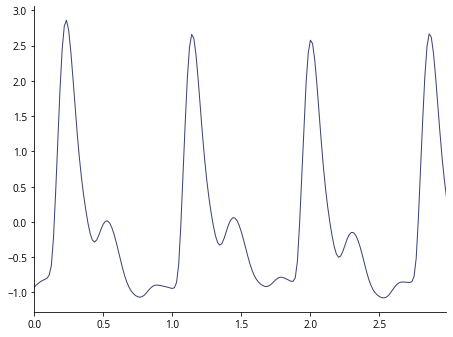

In [4]:
dur_plot = 3
fs_plot = 64
N_plot = int(dur_plot * fs_plot)
t_plot = jnp.arange(N_plot) / fs_plot

_, y_true = models.evaluate(t_plot,
                            true['z'],
                            true['w'],
                            true['f_h'],
                            true['g'],
                            true['a'],
                            true['b'],
                            true['f_b'],
                        )

plt.plot(t_plot, y_true)
plt.show()

In [5]:

def plot_exp(exp, title=None, desc=None, debug=False, legend=False):
    post_path = post_dir / f'{tagify(exp)}_post_samples.pkl'
    with open(post_path, 'rb') as f:
        post_samples = pickle.load(f)
    num_samples = len(post_samples['z'])

    prior_path = post_dir / f'{tagify(exp)}_prior_obs_init_config.pkl'
    with open(prior_path, 'rb') as f:
        (prior, obs, init, config) = pickle.load(f)
    t_obs = obs['t']
    y_obs = obs['y']

    if debug:
        K = 100
    else:
        K = num_samples
    ys = np.full((N_plot,K), np.nan)
    for i in trange(K):
        _, ys[:,i] = models.evaluate(t_plot,
                                    post_samples['z'][i],
                                    post_samples['w'][i],
                                    post_samples['f_h'][i],
                                    post_samples['g'][i],
                                    init['a'],
                                    init['b'],
                                    post_samples['f_b'][i],
                                    )

    map_path = post_dir / f'{tagify(exp)}_map.pkl'
    with open(map_path, 'rb') as f:
        map_sample = pickle.load(f)

    _, y_map = models.evaluate(t_plot,
                            map_sample['z'],
                            map_sample['w'],
                            map_sample['f_h'],
                            map_sample['g'],
                            map_sample['a'],
                            map_sample['b'],
                            map_sample['f_b'],
                            )

    plt.plot(t_plot, y_true, c='k', lw=1.5, zorder=-2, label='True signal')
    plt.plot(t_obs, y_obs, '.', c=cp[-1], zorder=-1, label='Noisy signal')
    plt.plot(t_plot, y_map, lw=1.5, c=cp[1], zorder=2, label='MAP')
    ci_lo, ci_hi = np.percentile(ys, 0.5, axis=1), np.percentile(ys, 99.5, axis=1)
    plt.fill_between(t_plot, ci_lo, ci_hi, color=cp[1], alpha=0.2, lw=0, zorder=0, label='95% CI')

    plt.yticks([])
    plt.xticks([])
    plt.ylim(-2, 4)
    plt.xlim(0, dur_plot)
    sns.despine(ax=plt.gca(), left=True, bottom=True, trim=True)

    if legend:
        plt.legend(loc='center left', bbox_to_anchor=(1.05, 0.5),
               ncol=1, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.5, handletextpad=0.5)

    if title:    
        plt.title(title, loc='left', pad=0, fontdict={'fontweight': 'bold'})

    if desc:
        plt.text(plt.xlim()[1], plt.ylim()[1], desc,
                 ha='right', va='top', bbox=dict(facecolor='white', alpha=0.5, lw=0))



In [6]:
def plot_kde(exp, legend=False):
    post_path = post_dir / f'{tagify(exp)}_post_samples.pkl'
    with open(post_path, 'rb') as f:
        post_samples = pickle.load(f)

    label = 'Pulse time KDE'
    for i in range(post_samples['z'].shape[1]):
        zis = post_samples['z'][:,i]
        if t_plot.min() < np.mean(zis) < t_plot.max():
            kde = gaussian_kde(zis)
            pdf = kde.evaluate(t_plot)
            plt.plot(t_plot, pdf/np.nanmax(pdf), c=cp[1], label=label)
            label = None
    plt.ylim(0, 1)
    plt.yticks([])
    plt.xticks([])
    sns.despine(ax=plt.gca(), left=True, trim=True)

    if legend:
        plt.legend(loc='center left', bbox_to_anchor=(1.05, 0.5),
               ncol=1, columnspacing=1.5,
               frameon=False, borderpad=0.0, borderaxespad=0.1,
               handlelength=1.5, handletextpad=0.5)


  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

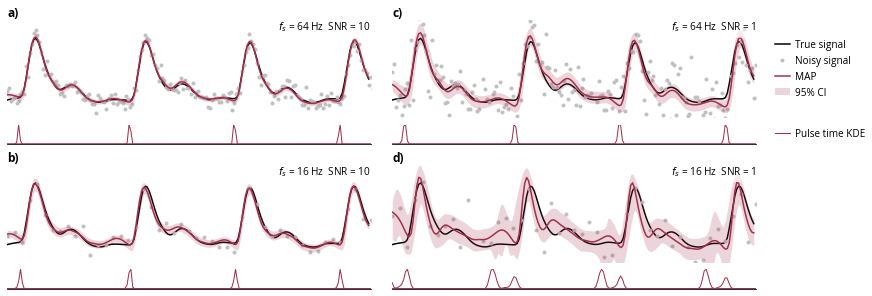

In [7]:
titles = ['a)', 'b)', 'c)', 'd)']

descify = lambda exp: f"$f_s$ = {exp['fs']} Hz  SNR = {exp['snr']}"
descs = [descify(exp) for exp in experiments]

debug = False

fig = plt.figure(figsize=(12,4), layout='constrained')
gs = GridSpec(4, 2, figure=fig,
              height_ratios=[5, 1, 5, 1], width_ratios = [1, 1],
              hspace=0.1, wspace=0.05,
              )
fig.add_subplot(gs[0, 0])
plot_exp(experiments[0], titles[0], descs[0], debug=debug)
fig.add_subplot(gs[1, 0])
plot_kde(experiments[0])

fig.add_subplot(gs[2, 0])
plot_exp(experiments[1], titles[1], descs[1], debug=debug)
fig.add_subplot(gs[3, 0])
plot_kde(experiments[1])

fig.add_subplot(gs[0, 1])
plot_exp(experiments[2], titles[2], descs[2], debug=debug, legend=True)
fig.add_subplot(gs[1, 1])
plot_kde(experiments[2], legend=True)

fig.add_subplot(gs[2, 1])
plot_exp(experiments[3], titles[3], descs[3], debug=debug)
fig.add_subplot(gs[3, 1])
plot_kde(experiments[3])

plt.savefig(f'{FIG}.pdf', transparent=True)
plt.savefig(f'{FIG}.png', transparent=True, dpi=200)
plt.show()

